# Salzer et al 2018

In [ ]:
import sys 
import os

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix
from scipy.stats import ttest_ind


from sklearn.preprocessing import MinMaxScaler, RobustScaler

from scipy import sparse

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12

sys.path.append('../../')
from stacked_barplots import plot_stacked_bar

sys.path.append('/media/amon/2TB-HD/Olga/Aging_and_transcriptional_noise/tools')
import transcriptional_noise as tn

seed=10

In [29]:
adata = sc.read('../../data/raw_data/salzer/Salzer.h5ad')

In [30]:
adata

AnnData object with n_obs × n_vars = 1044 × 50638
    obs: 'batch', 'sample', 'age', 'experiment'

In [45]:
adata = adata[adata.obs['age'].isin(['young', 'old'])]

In [46]:
sc.pp.filter_cells(adata, min_genes=50)
sc.pp.filter_genes(adata, min_cells=3)

Trying to set attribute `.obs` of view, copying.


In [47]:
adata

AnnData object with n_obs × n_vars = 661 × 16014
    obs: 'batch', 'sample', 'age', 'experiment', 'n_genes'
    var: 'n_cells'
    uns: 'log1p'

In [48]:
adata.X = csr_matrix(adata.X) # convert to sparse matrix

In [49]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [51]:
sc.pp.highly_variable_genes(adata)

In [52]:
sc.pp.pca(adata)

In [53]:
sce.pp.harmony_integrate(adata, key='batch')
sc.pp.neighbors(adata, use_rep='X_pca_harmony')
sc.tl.umap(adata)

2021-11-04 17:04:38,189 - harmonypy - INFO - Iteration 1 of 10
2021-11-04 17:04:38,554 - harmonypy - INFO - Iteration 2 of 10
2021-11-04 17:04:38,876 - harmonypy - INFO - Iteration 3 of 10
2021-11-04 17:04:39,132 - harmonypy - INFO - Iteration 4 of 10
2021-11-04 17:04:39,478 - harmonypy - INFO - Iteration 5 of 10
2021-11-04 17:04:39,724 - harmonypy - INFO - Iteration 6 of 10
2021-11-04 17:04:39,943 - harmonypy - INFO - Iteration 7 of 10
2021-11-04 17:04:40,131 - harmonypy - INFO - Converged after 7 iterations


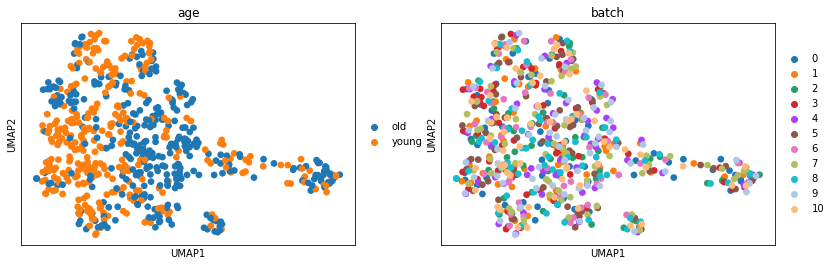

In [54]:
sc.pl.umap(adata, color=['age', 'batch'])

In [55]:
adata.obs

,batch,sample,age,experiment,n_genes
P2143_N704-S502,0,P2143,young,2,243
P2143_N704-S503,0,P2143,young,2,2569
P2143_N704-S504,0,P2143,young,2,2018
P2143_N704-S505,0,P2143,young,2,237
P2143_N704-S506,0,P2143,young,2,2724
...,...,...,...,...,...
P1960_N708-S504,10,P1960,old,1,1655
P1960_N708-S505,10,P1960,old,1,2078
P1960_N708-S506,10,P1960,old,1,2434
P1960_N708-S508,10,P1960,old,1,2155


In [57]:
adata.obs['cell_type'] = 'Fibroblasts'

In [59]:
adata.obs['condition'] = [age.capitalize() for age in adata.obs['age']]

In [72]:
adata.obs['batch'] = adata.obs['condition']

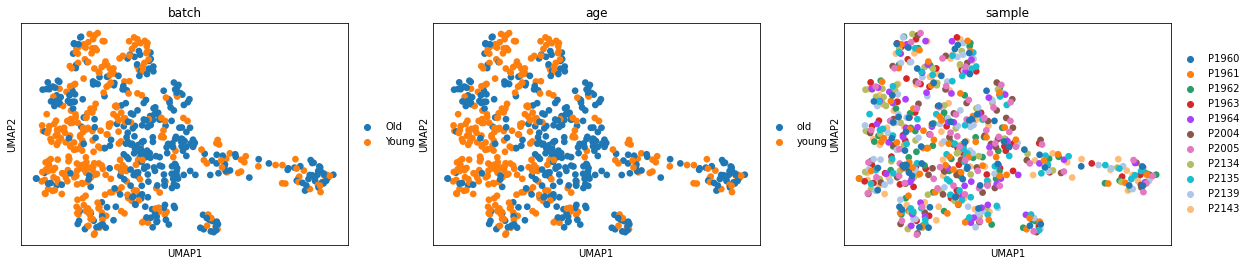

In [75]:
sc.pl.umap(adata, color=['batch', 'age', 'sample'])

In [74]:
adata.write('../../data/anndatas/annotated/Salzer.h5ad')